# Exploratory Data Analysis – GenAI Furniture Recommender (Sprint 1, Week 1)

This notebook analyses the actual repository datasets. Run it from the repository root (the folder containing `data/` and `outputs/`).

**Important scope note:** the current catalogue and behaviour samples are small (20 cleaned products and 12 behaviour events). The separate `Furniture.csv` contains 2,500 sales records with a different schema; it is analysed as supplementary sales data and is not counted as 2,500 unique products or users.

In [5]:
%pip install pandas numpy matplotlib seaborn

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'c:\\Users\\MONISHA GANGADIKAR L\\AppData\\Local\\Programs\\Python\\Python313\\Lib\\site-packages\\cycler\\__init__.py'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.7 MB 5.4 MB/s eta 0:00:02
   ------- -------------------------------- 2.1/10.7 MB 5.7 MB/s eta 0:00:02
   --------- ------------------------------ 2.6/10.7 MB 5.7 MB/s eta 0:00:02
   ------------- -------------------------- 3.7/10.7 MB 4.4 MB/s eta 0:00:02
   ------------------ --------------------- 5.0/10.7 MB 4.9 MB/s eta 0:00:02
   ------------------------ --------------- 6.6/10.7 MB 5.2 MB/s eta 0:00:01
   ----------------------------- ---------- 7.9/10.7 MB 5.3 MB/s eta 0:00:01
   --------------------------------- ------ 8.9/10.7 MB 5.3 MB/s eta 0:00:01
   ---------------------------------------  10.5/10.7 MB 5.5 MB/s eta 0:00:01
   --------------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Find the main project folder
ROOT = Path.cwd()

if not (ROOT / "outputs" / "product_features.csv").exists():
    ROOT = ROOT.parent

print("Project folder:", ROOT)

# Load datasets
products = pd.read_csv(ROOT / "outputs" / "product_features.csv")

behaviour = pd.read_csv(
    ROOT / "data" / "raw" / "user_behavior.csv"
)

customers = pd.read_csv(
    ROOT / "customer_feature_engineering" / "outputs" / "customer_features.csv"
)

sales = pd.read_csv(
    ROOT / "data" / "raw" / "Furniture.csv"
)

# Display dataset dimensions
print("Product features:", products.shape)
print("Behaviour events:", behaviour.shape)
print("Customer features:", customers.shape)
print("Supplementary sales records:", sales.shape)


Project folder: c:\Users\MONISHA GANGADIKAR L\Downloads\GenAI_Recommender_-FrameWorksA--main\GenAI_Recommender_-FrameWorksA--main
Product features: (20, 20)
Behaviour events: (12, 7)
Customer features: (10, 102)
Supplementary sales records: (2500, 15)


## 1. Data quality and completeness

In [4]:
# Complete missing value analysis

for name, df in {
    "Products": products,
    "Behaviour": behaviour,
    "Customers": customers,
    "Sales": sales
}.items():

    print("\n", "=" * 50)
    print(name.upper())
    print("=" * 50)

    missing = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": (
            df.isnull().sum() / len(df) * 100
        ).round(2)
    })

    print(missing.to_string())


PRODUCTS
                     Missing Count  Missing Percentage
product_id                       0                 0.0
product_name                     0                 0.0
category                         0                 0.0
category_group                   0                 0.0
category_subgroup                0                 0.0
material                         0                 0.0
colour                           0                 0.0
style                            0                 0.0
room_type                        0                 0.0
room_group                       0                 0.0
price                            1                 5.0
price_category                   0                 0.0
discount                         1                 5.0
rating                           0                 0.0
length_cm                       20               100.0
width_cm                        20               100.0
height_cm                       20               100.0


In [3]:
# Check dataset information

for name, df in {
    "products": products,
    "behaviour": behaviour,
    "customers": customers,
    "supplementary sales": sales
}.items():

    print("\nDATASET:", name.upper())

    print("Number of rows:", len(df))
    print("Number of columns:", len(df.columns))

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("-" * 50)


DATASET: PRODUCTS
Number of rows: 20
Number of columns: 20

Duplicate rows: 0

Missing values:
product_id              0
product_name            0
category                0
category_group          0
category_subgroup       0
material                0
colour                  0
style                   0
room_type               0
room_group              0
price                   1
price_category          0
discount                1
rating                  0
length_cm              20
width_cm               20
height_cm              20
dimensions_cm           0
product_description     0
embedding_text          0
dtype: int64
--------------------------------------------------

DATASET: BEHAVIOUR
Number of rows: 12
Number of columns: 7

Duplicate rows: 0

Missing values:
User_ID            0
Session_ID         0
Product_ID         0
Event_Type         0
Event_Timestamp    0
Device             0
Quantity           0
dtype: int64
--------------------------------------------------

DATASET: CUS

## 2. Product catalogue analysis

,product_id,product_name,category,material,colour,style,price,rating,room_type
0,P001,Modern Sofa,Sofa,Fabric,Beige,Modern,28500.0,4.5,Living Room
1,P002,Wooden Dining Table,Dining Table,Sheesham Wood,Brown,Traditional,32000.0,4.6,Dining Room
2,P003,Queen Size Bed,Bed,Engineered Wood,Walnut,Contemporary,41000.0,4.4,Bedroom
3,P004,Office Chair,Chair,Mesh,Black,Modern,NaN,4.2,Study Room
4,P005,Bookshelf,Storage,Plywood,White,Minimalist,8500.0,4.1,Study Room


Unique products: 20
Price summary:


count       19.000000
mean     18336.842105
std      13849.236262
min       3800.000000
25%       8500.000000
50%      13500.000000
75%      27250.000000
max      52000.000000
Name: price, dtype: float64

Category counts:


category
Storage         6
Chair           4
Table           3
Bed             2
Sofa            1
Dining Table    1
sofa            1
Lighting        1
Bench           1
Name: count, dtype: int64

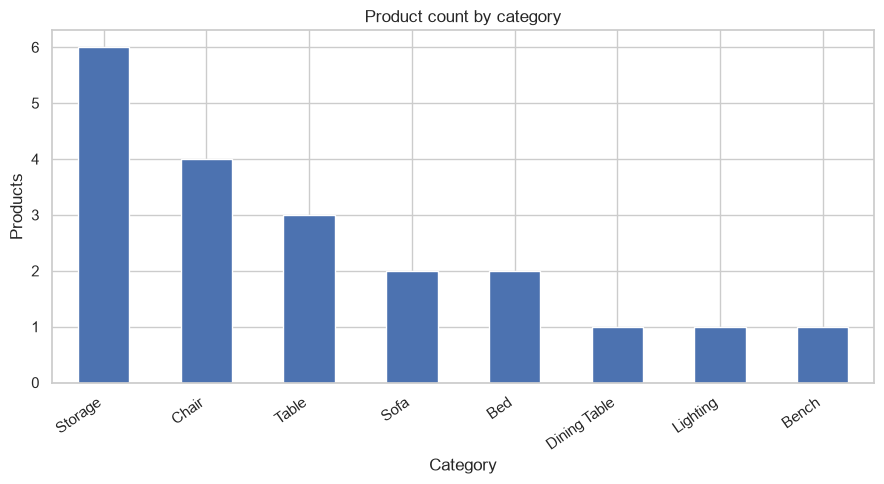

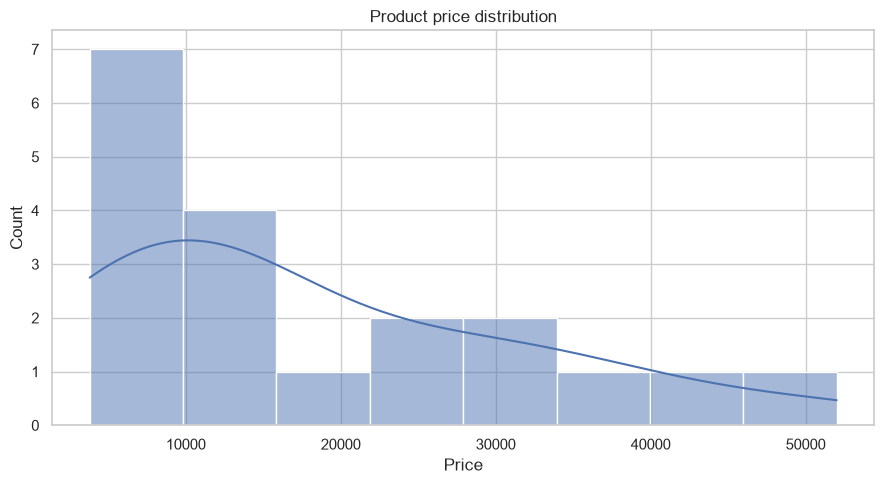

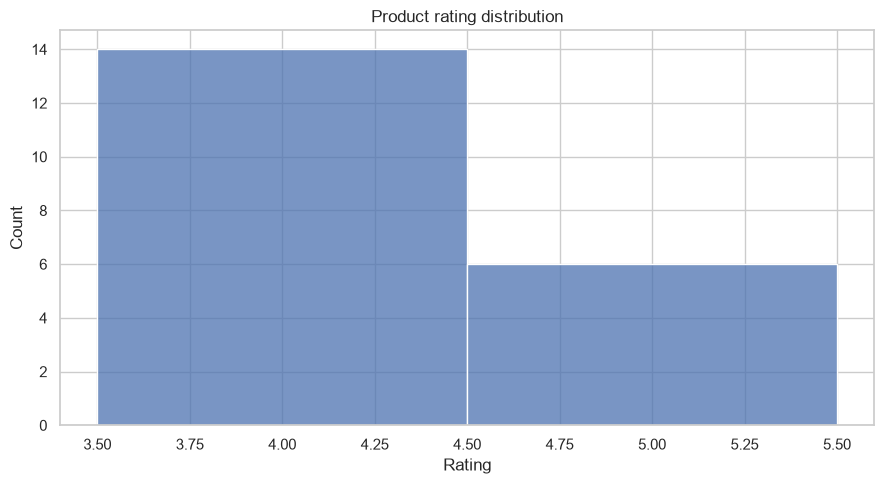

Average price by category:


category
Bed             46500.000000
Dining Table    32000.000000
Sofa            28500.000000
sofa            22000.000000
Chair           14766.666667
Storage         12716.666667
Table           12500.000000
Bench           11000.000000
Lighting         3800.000000
Name: price, dtype: float64

In [5]:
display(products[["product_id","product_name","category","material","colour","style","price","rating","room_type"]].head())
print("Unique products:", products["product_id"].nunique())
print("Price summary:")
display(products["price"].describe())
print("Category counts:")
display(products["category"].value_counts(dropna=False))

plt.figure(figsize=(9,5))
products["category"].astype(str).str.strip().str.title().value_counts().plot(kind="bar")
plt.title("Product count by category"); plt.xlabel("Category"); plt.ylabel("Products")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(9,5))
sns.histplot(products["price"].dropna(), bins=8, kde=True)
plt.title("Product price distribution"); plt.xlabel("Price"); plt.tight_layout(); plt.show()

plt.figure(figsize=(9,5))
sns.histplot(products["rating"].dropna(), bins=7, discrete=True)
plt.title("Product rating distribution"); plt.xlabel("Rating"); plt.tight_layout(); plt.show()

print("Average price by category:")
display(products.groupby("category", dropna=False)["price"].mean().sort_values(ascending=False))


## 3. Customer behaviour analysis

Event counts:


Event_Type
view           4
click          3
purchase       3
add_to_cart    2
Name: count, dtype: int64

Unique users: 10
Unique sessions: 10
Unique products interacted with: 9


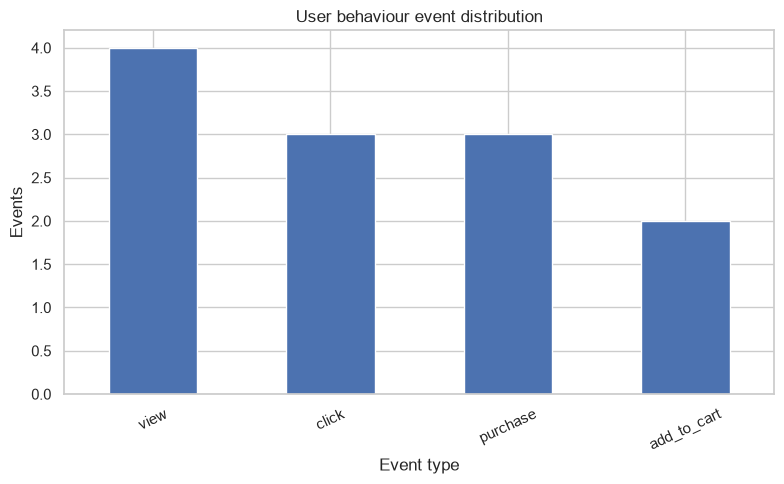

Device counts:


Device
Mobile     5
Desktop    4
Tablet     3
Name: count, dtype: int64

In [6]:
print("Event counts:")
display(behaviour["Event_Type"].value_counts())
print("Unique users:", behaviour["User_ID"].nunique())
print("Unique sessions:", behaviour["Session_ID"].nunique())
print("Unique products interacted with:", behaviour["Product_ID"].nunique())

plt.figure(figsize=(8,5))
behaviour["Event_Type"].value_counts().plot(kind="bar")
plt.title("User behaviour event distribution"); plt.xlabel("Event type"); plt.ylabel("Events")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()

print("Device counts:")
display(behaviour["Device"].value_counts())


## 4. Customer feature and RFM analysis

,user_id,total_interactions,total_purchases,total_spending,recency_days,frequency_score,monetary_score,rfm_score,customer_segment
0,U001,2,0,0.0,NaN,1,1.0,1-1-1,No Purchases
1,U002,2,0,0.0,NaN,1,1.0,1-1-1,No Purchases
2,U003,1,0,0.0,NaN,1,1.0,1-1-1,No Purchases
3,U004,1,1,NaN,1.0,3,NaN,3-3-NA,Spending Data Incomplete
4,U005,1,0,0.0,NaN,1,1.0,1-1-1,No Purchases
5,U006,1,1,28500.0,1.0,3,5.0,3-3-5,Regular Customers
6,U007,1,0,0.0,NaN,1,1.0,1-1-1,No Purchases
7,U008,1,0,0.0,NaN,1,1.0,1-1-1,No Purchases
8,U009,1,1,4200.0,1.0,3,3.0,3-3-3,Regular Customers
9,U010,1,0,0.0,NaN,1,1.0,1-1-1,No Purchases


Customer segments:


customer_segment
No Purchases                7
Regular Customers           2
Spending Data Incomplete    1
Name: count, dtype: int64

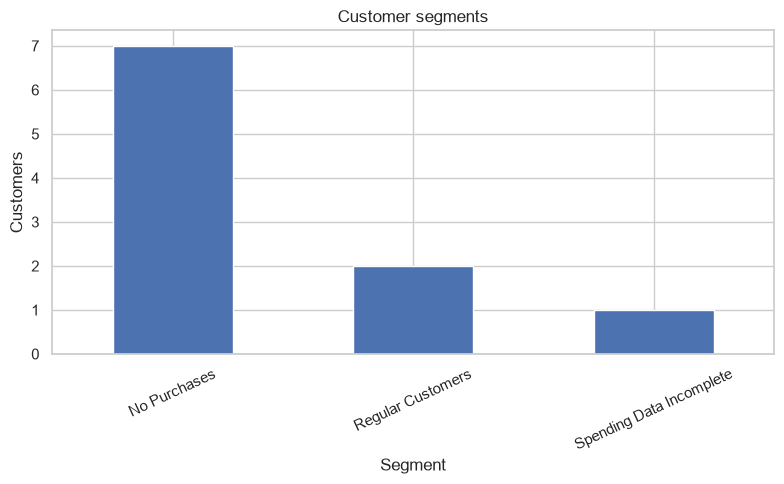

In [7]:
cols = [c for c in ["user_id","total_interactions","total_purchases","total_spending","recency_days","frequency_score","monetary_score","rfm_score","customer_segment"] if c in customers.columns]
display(customers[cols])
print("Customer segments:")
display(customers["customer_segment"].value_counts(dropna=False))

plt.figure(figsize=(8,5))
customers["customer_segment"].fillna("Unknown").value_counts().plot(kind="bar")
plt.title("Customer segments"); plt.xlabel("Segment"); plt.ylabel("Customers")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()


## 5. Supplementary sales dataset (Furniture.csv)

Sales dataset shape: (2500, 15)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,2500.0,NaN,NaN,NaN,274.495219,130.898452,50.704297,159.10489,277.641809,387.378046,499.872953
cost,2500.0,NaN,NaN,NaN,191.930107,98.590751,26.505895,106.399135,189.336329,263.18828,447.022911
sales,2500.0,NaN,NaN,NaN,24.924,14.050067,1.0,13.0,25.0,37.0,49.0
profit_margin,2500.0,NaN,NaN,NaN,30.208571,11.536804,10.017692,20.230697,30.297911,40.134205,49.999535
inventory,2500.0,NaN,NaN,NaN,97.7156,57.616228,0.0,50.0,94.0,147.0,199.0
discount_percentage,2500.0,NaN,NaN,NaN,14.947616,8.621547,0.005556,7.760214,14.915143,22.292661,29.991229
delivery_days,2500.0,NaN,NaN,NaN,4.894,2.55902,1.0,3.0,5.0,7.0,9.0
category,2500,5,Table,533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
material,2500,5,Metal,529,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color,2500,6,Black,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Category counts:


category
Table    533
Desk     501
Chair    497
Sofa     488
Bed      481
Name: count, dtype: int64

Store type counts:


store_type
Online    1307
Retail    1193
Name: count, dtype: int64

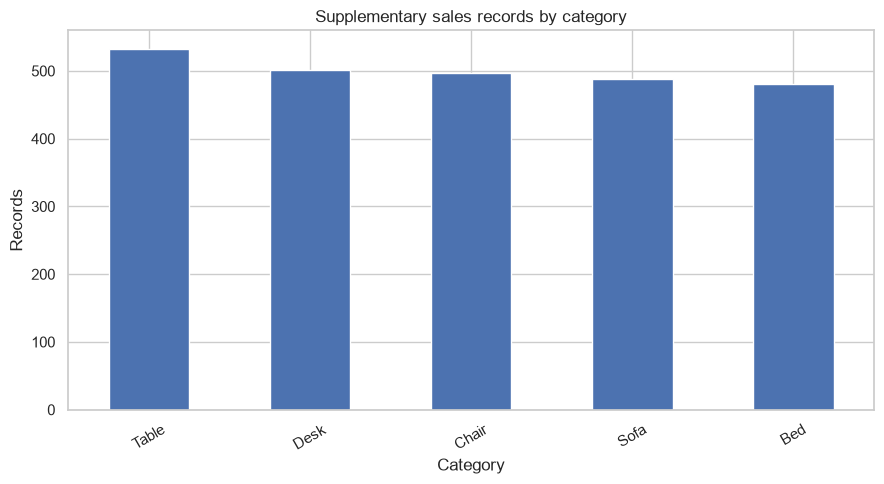

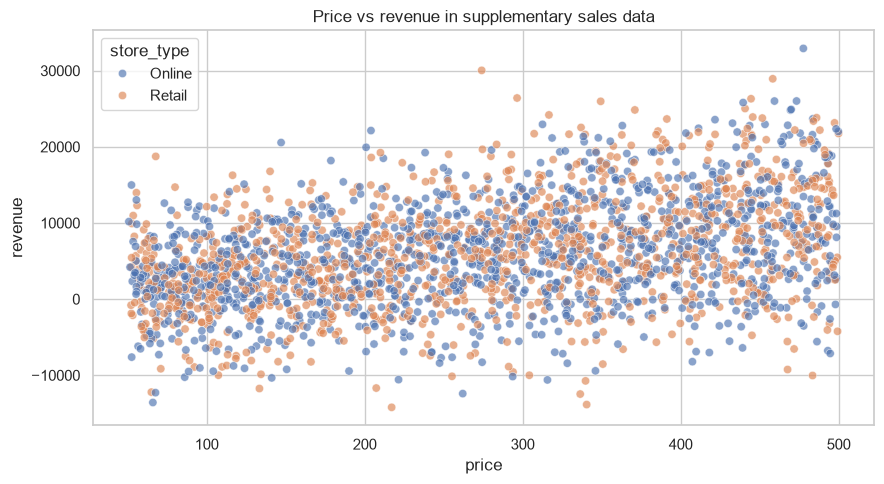

In [8]:
print("Sales dataset shape:", sales.shape)
display(sales.describe(include="all").T)
print("Category counts:")
display(sales["category"].value_counts())
print("Store type counts:")
display(sales["store_type"].value_counts())

plt.figure(figsize=(9,5))
sales["category"].value_counts().plot(kind="bar")
plt.title("Supplementary sales records by category"); plt.xlabel("Category"); plt.ylabel("Records")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

plt.figure(figsize=(9,5))
sns.scatterplot(data=sales, x="price", y="revenue", hue="store_type", alpha=.65)
plt.title("Price vs revenue in supplementary sales data"); plt.tight_layout(); plt.show()


## 6. Findings and limitations

- The product feature output contains 20 product records; the current raw product file contains 21 rows.
- The raw behaviour file contains 12 events from 10 distinct users. This is too small to represent the required 2,000+ user population.
- Product dimensions (`length_cm`, `width_cm`, `height_cm`) are missing for all 20 products in the current product feature output.
- The supplementary `Furniture.csv` has 2,500 rows and a sales-oriented schema. Its rows are sales records, not verified unique products or customer behaviour records.
- RFM values should be interpreted cautiously because there are only 10 customers and 12 behaviour events. Several customers have no purchase event, so recency/spending can be missing or zero.
- Expand the synthetic catalogue and behaviour data before using the dataset for robust recommender model training.